# Imputation experiment (data v2, multi-seed)

Input: `final_df_(distance)_v2.parquet` (the corrected transform output).

What changed compared with the previous notebook:

1. **Multi-seed**: every mechanism x missing rate x method is repeated for several random seeds; the summary reports mean and standard deviation.
2. The old exploratory KNN cells (standardized values written back without `inverse_transform`) were removed. Only the corrected `knn_impute` remains.
3. Results are saved under **new file names** (`..._datav2.csv`), old result files are not overwritten. Injected datasets of the first seed go to `exp_data_v2/`.
4. All Mean / Median / KNN / MICE runs are produced by one loop, so no hard-coded numbers and no duplicated functions.
5. The meaningless `corr_matrix.corr()` was removed.

Run with **Restart Kernel and Run All**. After the first seed finishes, the notebook prints the elapsed time, so you can decide whether to add more seeds (`SEEDS`).

## 0. Setup

In [17]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, KNNImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler

# ---- paths -------------------------------------------------------------
BASE = Path("/Users/sivhoung/Desktop/Year 4 intern project/Project code ")
DATA_PATH = BASE / "dataset" / "processed dataset" / "final_df_(distance)_v2.parquet"
EXP_DIR = BASE / "dataset" / "exp_data_v2"
RESULTS_DIR = BASE / "results"
EXP_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

SUFFIX = "datav2"
RAW_FILE = RESULTS_DIR / f"imputation_results_raw_{SUFFIX}.csv"
SUMMARY_FILE = RESULTS_DIR / f"imputation_results_summary_{SUFFIX}.csv"
SEED_ONE_FILE = RESULTS_DIR / f"imputation_results_seed42_{SUFFIX}.csv"

# ---- experiment settings -----------------------------------------------
SEEDS = [42, 1, 7, 21, 100]              # add more seeds if the run time allows
RATES = [0.10, 0.30, 0.50]
MECHANISMS = ["MCAR", "MAR", "MNAR"]
TARGET = "total_freight_value"        # variable that receives the missing values
AUXILIARY = "total_product_weight_g"  # drives the MAR mechanism

FEATURES = [
    "total_price",
    "total_freight_value",
    "total_product_weight_g",
    "average_product_length_cm",
    "average_product_height_cm",
    "item_count",
    "max_payment_installments",
    "average_distance_km",
]

## 1. Load data

In [18]:
df = pd.read_parquet("/Users/sivhoung/Desktop/Year 4 intern project/Project code /dataset/processed dataset/final_df_(distance)_v2.parquet")
print("full dataset:", df.shape)

experiment_columns = ["order_id", *FEATURES, "is_delayed"]
model_df = df[experiment_columns].dropna().copy()

print("complete-case dataset:", model_df.shape)
print("missing values left:", int(model_df.isna().sum().sum()))
print("share delayed:", round(float(model_df["is_delayed"].astype(float).mean()), 4))

full dataset: (99418, 28)
complete-case dataset: (95959, 10)
missing values left: 0
share delayed: 0.0676


## 2. Correlation overview

average_distance_km         -0.075840
total_freight_value         -0.049377
item_count                  -0.031624
max_payment_installments    -0.031055
total_price                 -0.013045
average_product_height_cm   -0.002287
total_product_weight_g       0.002342
average_product_length_cm    0.009616
delivery_delay_days          1.000000
Name: delivery_delay_days, dtype: float64


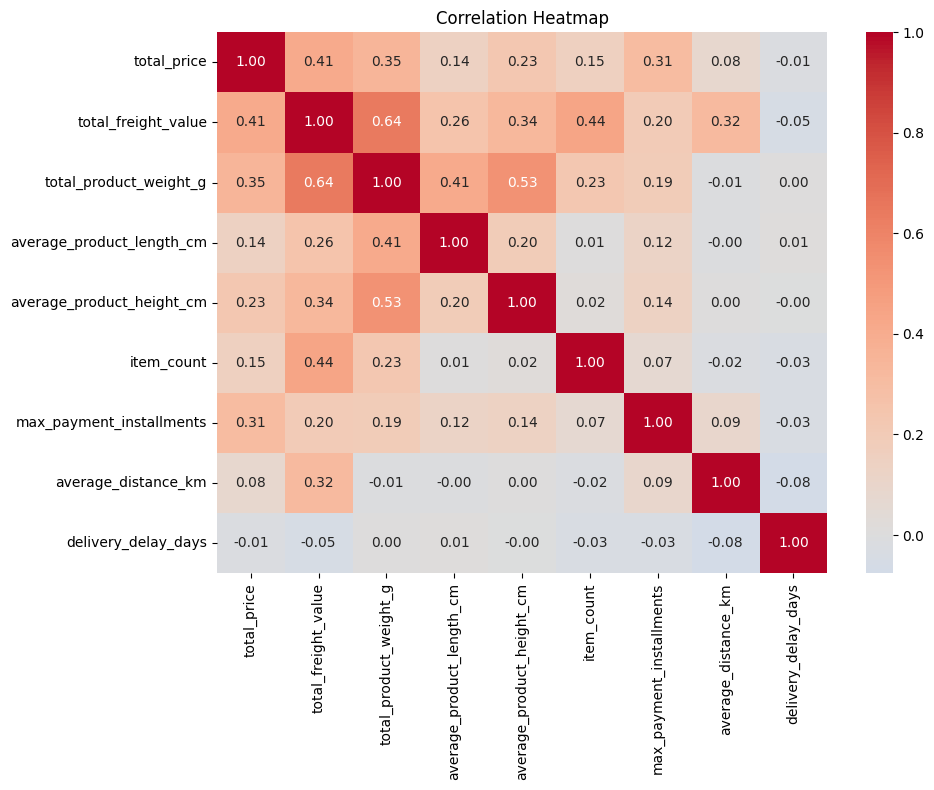

In [19]:
corr_df = df.dropna(subset=FEATURES + ["is_delayed"])

print(
    corr_df[FEATURES + ["delivery_delay_days"]]
    .corr()["delivery_delay_days"]
    .sort_values()
)

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_df[FEATURES + ["delivery_delay_days"]].corr(),
    annot=True, cmap="coolwarm", center=0, fmt=".2f",
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## 3. Missing-data injection

In [20]:
def inject_mcar(df, target, missing_rate, random_seed=42):
    df_injected = df.copy()
    rng = np.random.default_rng(random_seed)

    n_missing = int(len(df_injected) * missing_rate)
    missing_indices = rng.choice(df_injected.index, size=n_missing, replace=False)

    df_injected.loc[missing_indices, target] = np.nan
    return df_injected


def inject_mar(df, target, auxiliary, missing_rate, random_seed=42):
    # higher auxiliary value -> higher probability of being set to missing
    df_injected = df.copy()
    rng = np.random.default_rng(random_seed)

    weights = df_injected[auxiliary].rank(pct=True).to_numpy() + 0.01
    weights = weights / weights.sum()

    n_missing = int(len(df_injected) * missing_rate)
    missing_indices = rng.choice(
        df_injected.index, size=n_missing, replace=False, p=weights
    )

    df_injected.loc[missing_indices, target] = np.nan
    return df_injected


def inject_mnar(df, target, missing_rate, random_seed=42):
    # higher target value -> higher probability of being set to missing
    df_injected = df.copy()
    rng = np.random.default_rng(random_seed)

    weights = df_injected[target].rank(pct=True).to_numpy() + 0.01
    weights = weights / weights.sum()

    n_missing = int(len(df_injected) * missing_rate)
    missing_indices = rng.choice(
        df_injected.index, size=n_missing, replace=False, p=weights
    )

    df_injected.loc[missing_indices, target] = np.nan
    return df_injected


def make_injected(df, mechanism, rate, seed):
    if mechanism == "MCAR":
        return inject_mcar(df, TARGET, rate, seed)
    if mechanism == "MAR":
        return inject_mar(df, TARGET, AUXILIARY, rate, seed)
    if mechanism == "MNAR":
        return inject_mnar(df, TARGET, rate, seed)
    raise ValueError(mechanism)

### 3.1 Validate the mechanisms (first seed)

MAR: records with missing `total_freight_value` should have a higher mean `total_product_weight_g` than observed records.
MNAR: records with missing `total_freight_value` should have a higher mean `total_freight_value` (original values).
MCAR: both groups should have similar means.

In [21]:
check_rows = []
for mechanism in MECHANISMS:
    for rate in RATES:
        injected = make_injected(model_df, mechanism, rate, SEEDS[0])
        is_missing = injected[TARGET].isna()
        column = AUXILIARY if mechanism == "MAR" else TARGET
        check_rows.append({
            "mechanism": mechanism,
            "target_rate": rate,
            "actual_rate": round(float(is_missing.mean()), 4),
            "checked_column": column,
            "mean_missing_group": round(float(model_df.loc[is_missing, column].mean()), 2),
            "mean_observed_group": round(float(model_df.loc[~is_missing, column].mean()), 2),
        })

pd.DataFrame(check_rows)

,mechanism,target_rate,actual_rate,checked_column,mean_missing_group,mean_observed_group
0,MCAR,0.1,0.1,total_freight_value,22.21,22.84
1,MCAR,0.3,0.3,total_freight_value,22.58,22.86
2,MCAR,0.5,0.5,total_freight_value,22.66,22.89
3,MAR,0.1,0.1,total_product_weight_g,4025.59,2202.22
4,MAR,0.3,0.3,total_product_weight_g,3689.24,1825.40
5,MAR,0.5,0.5,total_product_weight_g,3432.44,1336.66
6,MNAR,0.1,0.1,total_freight_value,30.53,21.92
7,MNAR,0.3,0.3,total_freight_value,29.26,20.00
8,MNAR,0.5,0.5,total_freight_value,28.00,17.55


In [22]:
# Save the injected datasets of the first seed (for reproducibility / inspection)
for mechanism in MECHANISMS:
    for rate in RATES:
        injected = make_injected(model_df, mechanism, rate, SEEDS[0])
        injected.to_parquet(EXP_DIR / f"{mechanism.lower()}_{int(rate * 100)}.parquet", index=False)

sorted(p.name for p in EXP_DIR.glob("*.parquet"))

['mar_10.parquet',
 'mar_30.parquet',
 'mar_50.parquet',
 'mcar_10.parquet',
 'mcar_30.parquet',
 'mcar_50.parquet',
 'mnar_10.parquet',
 'mnar_30.parquet',
 'mnar_50.parquet']

## 4. Imputation methods and evaluation

In [23]:
def mean_impute(df, target):
    df_imputed = df.copy()
    df_imputed[target] = df_imputed[target].fillna(df_imputed[target].mean())
    return df_imputed


def median_impute(df, target):
    df_imputed = df.copy()
    df_imputed[target] = df_imputed[target].fillna(df_imputed[target].median())
    return df_imputed


def knn_impute(df, features, n_neighbors=5):
    df_imputed = df.copy()

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(df_imputed[features])

    imputer = KNNImputer(n_neighbors=n_neighbors, weights="uniform")
    X_imputed_scaled = imputer.fit_transform(X_scaled)

    # back to the original scale before comparing with the ground truth
    X_imputed = scaler.inverse_transform(X_imputed_scaled)

    df_imputed[features] = pd.DataFrame(X_imputed, columns=features, index=df.index)
    return df_imputed


def mice_impute(df, features, n_iter=10, random_seed=42):
    df_imputed = df.copy()

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(df_imputed[features])

    imputer = IterativeImputer(max_iter=n_iter, random_state=random_seed)
    X_imputed_scaled = imputer.fit_transform(X_scaled)

    X_imputed = scaler.inverse_transform(X_imputed_scaled)

    df_imputed[features] = pd.DataFrame(X_imputed, columns=features, index=df.index)
    return df_imputed


def evaluate_imputation(original_df, imputed_df, mask, target):
    original_values = original_df.loc[mask, target]
    imputed_values = imputed_df.loc[mask, target]

    mae = mean_absolute_error(original_values, imputed_values)
    rmse = np.sqrt(mean_squared_error(original_values, imputed_values))
    return mae, rmse


METHODS = {
    "Mean":   lambda data, seed: mean_impute(data, TARGET),
    "Median": lambda data, seed: median_impute(data, TARGET),
    "KNN":    lambda data, seed: knn_impute(data, FEATURES, n_neighbors=5),
    "MICE":   lambda data, seed: mice_impute(data, FEATURES, n_iter=10, random_seed=seed),
}

## 5. Run all experiments

For every seed: inject missing values (3 mechanisms x 3 rates), impute with all four methods, evaluate only on the injected positions against the original values. The raw results are written after every seed, so a partial run is never lost.

In [24]:
raw_rows = []
t_start = time.time()

for seed in SEEDS:
    t_seed = time.time()

    for mechanism in MECHANISMS:
        for rate in RATES:
            injected = make_injected(model_df, mechanism, rate, seed)
            mask = injected[TARGET].isna()

            for method, impute_fn in METHODS.items():
                t0 = time.time()
                imputed = impute_fn(injected, seed)

                assert imputed[TARGET].notna().all(), f"{method}: missing values left"

                mae, rmse = evaluate_imputation(model_df, imputed, mask, TARGET)
                raw_rows.append({
                    "mechanism": mechanism,
                    "missing_rate": rate,
                    "method": method,
                    "seed": seed,
                    "MAE": mae,
                    "RMSE": rmse,
                    "seconds": round(time.time() - t0, 2),
                })

    raw_df = pd.DataFrame(raw_rows)
    raw_df.to_csv(RAW_FILE, index=False)
    print(
        f"seed {seed} done in {(time.time() - t_seed) / 60:.1f} min "
        f"(total {(time.time() - t_start) / 60:.1f} min)"
    )

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: in

seed 42 done in 6.9 min (total 6.9 min)


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: in

seed 1 done in 7.3 min (total 14.1 min)


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: in

...

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: in

seed 21 done in 6.9 min (total 28.1 min)


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: in

seed 100 done in 7.0 min (total 35.0 min)


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self

## 6. Results

In [25]:
summary = (
    raw_df
    .groupby(["method", "mechanism", "missing_rate"])
    .agg(
        MAE_mean=("MAE", "mean"),
        MAE_std=("MAE", "std"),
        RMSE_mean=("RMSE", "mean"),
        RMSE_std=("RMSE", "std"),
        n_runs=("seed", "nunique"),
    )
    .reset_index()
    .sort_values(["method", "mechanism", "missing_rate"])
    .reset_index(drop=True)
)

summary.to_csv(SUMMARY_FILE, index=False)

# same layout as the old single-run file (first seed only)
seed_one = (
    raw_df[raw_df["seed"] == SEEDS[0]]
    [["mechanism", "missing_rate", "method", "MAE", "RMSE"]]
    .sort_values(["method", "mechanism", "missing_rate"])
    .reset_index(drop=True)
)
seed_one.to_csv(SEED_ONE_FILE, index=False)

summary

,method,mechanism,missing_rate,MAE_mean,MAE_std,RMSE_mean,RMSE_std,n_runs
0,KNN,MAR,0.1,6.960482,0.140124,15.150598,0.626135,5
1,KNN,MAR,0.3,6.825384,0.046606,16.877280,0.973343,5
2,KNN,MAR,0.5,6.671061,0.028096,15.984233,0.543670,5
3,KNN,MCAR,0.1,5.063684,0.113482,11.778368,0.820127,5
4,KNN,MCAR,0.3,5.171233,0.061090,13.534406,1.576871,5
5,KNN,MCAR,0.5,5.250988,0.056034,13.220132,0.881116,5
6,KNN,MNAR,0.1,7.472212,0.118670,16.343175,0.624845,5
7,KNN,MNAR,0.3,7.256914,0.084437,17.771268,1.337034,5
8,KNN,MNAR,0.5,7.072034,0.036548,16.670637,0.666055,5
9,MICE,MAR,0.1,7.892628,0.155115,15.659439,0.727592,5


In [26]:
expected_rows = len(METHODS) * len(MECHANISMS) * len(RATES)
print("summary rows:", len(summary), "| expected:", expected_rows)
print("runs per cell:", summary["n_runs"].unique())
print("NaN in raw results:", int(raw_df[["MAE", "RMSE"]].isna().sum().sum()))
print("duplicate cells:", int(summary.duplicated(["method", "mechanism", "missing_rate"]).sum()))

summary rows: 36 | expected: 36
runs per cell: [5]
NaN in raw results: 0
duplicate cells: 0


In [27]:
# MAE (mean over seeds): rows = method, columns = mechanism x missing rate
summary.pivot_table(
    index="method",
    columns=["mechanism", "missing_rate"],
    values="MAE_mean",
).round(2)

mechanism       MAR                 MCAR                 MNAR              
missing_rate    0.1    0.3    0.5    0.1    0.3    0.5    0.1    0.3    0.5
method                                                                     
KNN            6.96   6.83   6.67   5.06   5.17   5.25   7.47   7.26   7.07
MICE           7.89   7.57   7.26   5.82   5.90   5.93   8.15   7.80   7.36
Mean          13.45  12.72  12.06  11.23  11.35  11.36  13.49  12.81  12.40
Median        13.36  12.81  12.43   9.66   9.83   9.84  14.57  14.17  13.60

In [28]:
# RMSE (mean over seeds)
summary.pivot_table(
    index="method",
    columns=["mechanism", "missing_rate"],
    values="RMSE_mean",
).round(2) 

mechanism       MAR                 MCAR                 MNAR              
missing_rate    0.1    0.3    0.5    0.1    0.3    0.5    0.1    0.3    0.5
method                                                                     
KNN           15.15  16.88  15.98  11.78  13.53  13.22  16.34  17.77  16.67
MICE          15.66  16.97  15.94  11.70  13.64  13.28  16.58  17.47  16.19
Mean          26.33  27.40  26.35  20.24  22.09  21.74  28.23  28.61  27.44
Median        27.87  28.70  27.48  20.94  22.79  22.46  30.14  30.24  28.47

## Notes for the report

- Each cell of the result table is the mean over `len(SEEDS)` independent random injections; report the standard deviation (`MAE_std`, `RMSE_std`) next to it, or at least state the number of runs.
- Evaluation uses only the injected positions and compares against the original values, so no train/test split is needed for this part.
- Output files carry the suffix `datav2`; the earlier results from the previous data remain untouched.

result save to 

results/imputation_results_raw_datav2.csv
results/imputation_results_summary_datav2.csv
results/imputation_results_seed42_datav2.csv